# ЛР №4. Скалярное автоматическое дифференцирование

Нужно реализовать класс `Value`, проверить производные и обучить один tanh-нейрон.
Данные заданы ниже. Для вычислений достаточно модуля `math`.

Материалы: `lab_guide.pdf`, `theory.pdf`, `product_rule_debugging.pdf`.


In [1]:
# AUTOGRAD_ESSENTIALS_CELL: imports_and_helper
"""Скалярный autograd и контрольные эксперименты на стандартном Python."""

import math


def assert_close(actual, expected, tolerance=1e-9):
    """Проверить абсолютную погрешность двух вещественных чисел."""
    difference = abs(actual - expected)
    assert difference <= tolerance, (
        f"Ожидалось {expected}, получено {actual}, абсолютная ошибка {difference}"
    )

## Подготовка

Установка вычислительных пакетов не требуется: нужен обычный Python
и интерфейс для открытия `.ipynb`. `assert_close` сравнивает числа
с абсолютным допуском, учитывая погрешность арифметики `float`.

Различаем два прохода: прямой вычисляет значения и строит граф,
обратный получает производные итогового скаляра по вершинам графа.
Автоматическое дифференцирование соединяет точные локальные производные
правилом цепочки; конечные разности используются только как независимая проверка.


## Часть первая: класс Value

Каждая вершина содержит одно вещественное число:

| Поле | Что хранит |
|---|---|
| `data` | Результат прямого вычисления |
| `grad` | Накопленную производную итоговой функции по этой вершине |
| `parents` | Кортеж ссылок на непосредственные входы операции |
| `op` | Читаемую метку операции |
| `_backward` | Замыкание с локальным правилом передачи градиента |

Для $z=f(x,y)$ при известном $g_z=\partial J/\partial z$
прибавляем $g_z\partial z/\partial x$ в `x.grad` и
$g_z\partial z/\partial y$ в `y.grad`.
Используется `+=`, поскольку одна вершина может влиять на результат несколькими путями.

Метод `backward` сначала строит топологический порядок «родители перед потомками»,
обнуляет градиенты достижимого подграфа, устанавливает градиент результата в 1
и вызывает локальные правила в обратном порядке.
Реализация следует методичке; добавлены docstrings для пояснения методов.


In [2]:
# AUTOGRAD_ESSENTIALS_CELL: value
class Value:
    """Хранить скаляр, его родителей и локальное правило обратного прохода."""

    def __init__(self, data, parents=(), op=""):
        """Создать вершину с нулевым градиентом и заданными родителями."""
        self.data = float(data)
        self.grad = 0.0
        self.parents = parents
        self.op = op
        self._backward = lambda: None

    def __repr__(self):
        """Вернуть читаемые данные, градиент и метку операции."""
        return f"Value(data={self.data:.6g}, grad={self.grad:.6g}, op={self.op!r})"

    def __add__(self, other):
        """Сложить два скаляра и сохранить локальные производные суммы."""
        other = other if isinstance(other, Value) else Value(other)
        result = Value(self.data + other.data, parents=(self, other), op="+")

        def backward():
            self.grad += result.grad
            other.grad += result.grad

        result._backward = backward
        return result

    __radd__ = __add__

    def __mul__(self, other):
        """Умножить два скаляра и сохранить производные по обоим множителям."""
        other = other if isinstance(other, Value) else Value(other)
        result = Value(self.data * other.data, parents=(self, other), op="*")

        def backward():
            self.grad += result.grad * other.data
            other.grad += result.grad * self.data

        result._backward = backward
        return result

    __rmul__ = __mul__

    def __neg__(self):
        """Изменить знак скаляра с локальной производной минус один."""
        result = Value(-self.data, parents=(self,), op="neg")

        def backward():
            self.grad += result.grad * (-1)

        result._backward = backward
        return result

    def __sub__(self, other):
        """Представить вычитание как сложение с отрицанием."""
        return self + (-other)

    def __rsub__(self, other):
        """Вычесть текущую вершину из обычного числа или другого Value."""
        return other + (-self)

    def __pow__(self, power):
        """Возвести скаляр в постоянную степень и сохранить её производную."""
        result = Value(self.data**power, parents=(self,), op=f"pow({power})")

        def backward():
            local_derivative = power * self.data ** (power - 1)
            self.grad += result.grad * local_derivative

        result._backward = backward
        return result

    def sin(self):
        """Вычислить синус и сохранить множитель cos для обратного прохода."""
        result = Value(math.sin(self.data), parents=(self,), op="sin")

        def backward():
            self.grad += result.grad * math.cos(self.data)

        result._backward = backward
        return result

    def exp(self):
        """Вычислить экспоненту и использовать её значение как производную."""
        result = Value(math.exp(self.data), parents=(self,), op="exp")

        def backward():
            self.grad += result.grad * result.data

        result._backward = backward
        return result

    def log(self):
        """Вычислить натуральный логарифм положительного скаляра."""
        result = Value(math.log(self.data), parents=(self,), op="log")

        def backward():
            self.grad += result.grad * (1 / self.data)

        result._backward = backward
        return result

    def tanh(self):
        """Вычислить tanh и сохранить множитель 1 - tanh(x)**2."""
        result = Value(math.tanh(self.data), parents=(self,), op="tanh")

        def backward():
            self.grad += result.grad * (1 - result.data**2)

        result._backward = backward
        return result

    def backward(self):
        """Вычислить градиенты достижимого графа в обратном топологическом порядке."""
        topo = []
        visited = set()

        def build(node):
            if node not in visited:
                visited.add(node)
                for parent in node.parents:
                    build(parent)
                topo.append(node)

        build(self)
        for node in topo:
            node.grad = 0.0
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

## Прямой проход: сложение

Для $z=x+y$ локальные производные равны 1, поэтому в обратном проходе
каждый родитель получает вклад `result.grad`. При $x=2.5$, $y=-1$
значение суммы равно 1.5. Проверяем также ссылки на родителей и метку операции.


In [3]:
# AUTOGRAD_ESSENTIALS_CELL: addition_experiment
left = Value(2.5)
right = Value(-1.0)
sum_value = left + right

assert_close(sum_value.data, 1.5)
assert sum_value.parents == (left, right)
assert sum_value.op == "+"
print("Сложение в прямом проходе: OK")

Сложение в прямом проходе: OK


## Прямой проход: умножение

Для $z=xy$ имеем $\partial z/\partial x=y$ и $\partial z/\partial y=x$.
Поэтому градиент каждого множителя умножается на значение другого.
Проверка даёт $4\cdot(-0.5)=-2$ и $3\cdot4=12$;
отражённый метод `__rmul__` поддерживает число слева от `Value`.


In [4]:
# AUTOGRAD_ESSENTIALS_CELL: multiplication_experiment
left = Value(4.0)
right = Value(-0.5)
product_value = left * right
scaled_value = 3.0 * left

assert_close(product_value.data, -2.0)
assert_close(scaled_value.data, 12.0)
assert product_value.parents == (left, right)
assert product_value.op == "*"
print("Умножение в прямом проходе: OK")

Умножение в прямом проходе: OK


## Прямой проход: отрицание, вычитание и степень

Используем $(-x)'=-1$, $x-y=x+(-y)$ и $(x^p)'=px^{p-1}$
при постоянном показателе. Для $x=3$ получаем $-x=-3$,
$5-x=2$ и $x^3=27$. Производная по самому показателю степени не вычисляется.


In [5]:
# AUTOGRAD_ESSENTIALS_CELL: neg_sub_power_experiment
source = Value(3.0)
negative = -source
difference = 5.0 - source
cube = source**3

assert_close(negative.data, -3.0)
assert_close(difference.data, 2.0)
assert_close(cube.data, 27.0)
assert negative.op == "neg"
assert cube.op == "pow(3)"
print("Отрицание, вычитание и степень в прямом проходе: OK")

Отрицание, вычитание и степень в прямом проходе: OK


## Прямой проход: элементарные функции

| Операция | Локальная производная |
|---|---|
| $\sin x$ | $\cos x$ |
| $\exp x$ | $\exp x$ |
| $\log x$, $x>0$ | $1/x$ |
| $\tanh x$ | $1-\tanh^2 x$ |

В прямом проходе проверяем синус нуля, композицию `exp().log()`
и совпадение `tanh` с `math.tanh`.


In [6]:
# AUTOGRAD_ESSENTIALS_CELL: elementary_experiment
angle = Value(0.0)
positive = Value(2.0)
activation_input = Value(0.7)

assert_close(angle.sin().data, 0.0)
assert_close(positive.exp().log().data, 2.0)
assert_close(activation_input.tanh().data, math.tanh(0.7))
print("Элементарные функции в прямом проходе: OK")

Элементарные функции в прямом проходе: OK


## Обратный проход и общий узел графа

Для $f(a)=a^2+a$ обычное дифференцирование даёт $f'(a)=2a+1$.
При $a=2$ значение равно 6, а производная равна 5.
В умножении `a*a` обе ссылки ведут к одному объекту, поэтому два локальных
вклада равны $a+a=4$. Сложение `+a` добавляет ещё 1.

`visited` посещает вершину один раз, но не удаляет повторные рёбра
из `parents=(a,a)`. Поэтому обе строки локального умножения выполняются
и правильно складывают вклады. Замена `+=` на `=` потеряла бы часть производной.


In [7]:
# AUTOGRAD_ESSENTIALS_CELL: backward_shared_graph
a = Value(2.0)
objective = a * a + a
objective.backward()

assert_close(objective.data, 6.0)
assert_close(a.grad, 5.0)
assert_close(objective.grad, 1.0)
print("Обратный проход и накопление двух вкладов: OK")

Обратный проход и накопление двух вкладов: OK


## Ручная трассировка локального обратного прохода

Для $m=ab$, $s=m+a$, $J=\tanh s$ при $a=0.5$, $b=1$ получаем
$m=0.5$, $s=1$, $J\approx0.761594156$.
Полагаем $g_J=1$, затем вызываем ровно те локальные замыкания,
которые обычный `backward` вызвал бы сам.

| Шаг | Результат |
|---|---|
| `j._backward()` | $g_s=1-J^2\approx0.419974342$ |
| `s._backward()` | $g_m\approx0.419974342$ и первый вклад в $g_a\approx0.419974342$ |
| `m._backward()` | $g_a=g_s(1+b)\approx0.839948683$, $g_b=g_sa\approx0.209987171$ |

Ручной вызов `_backward` используется только в диагностике.
Во время обучения вызывается полный метод `loss.backward()`.


In [8]:
# AUTOGRAD_ESSENTIALS_CELL: manual_backward_trace
a = Value(0.5)
b = Value(1.0)
m = a * b
s = m + a
j = s.tanh()

for node in (a, b, m, s, j):
    node.grad = 0.0

j.grad = 1.0
expected_gs = 1.0 - j.data**2
j._backward()
assert_close(s.grad, expected_gs)
assert_close(m.grad, 0.0)
assert_close(a.grad, 0.0)
print("После J._backward():", "g_s =", s.grad)

s._backward()
assert_close(m.grad, expected_gs)
assert_close(a.grad, expected_gs)
print("После s._backward():", "g_m =", m.grad, "; первый вклад в g_a =", a.grad)

m._backward()
assert_close(a.grad, expected_gs * (1.0 + b.data))
assert_close(b.grad, expected_gs * a.data)
print("После m._backward():", "g_a =", a.grad, "; g_b =", b.grad)

После J._backward(): g_s = 0.41997434161402614
После s._backward(): g_m = 0.41997434161402614 ; первый вклад в g_a = 0.41997434161402614
После m._backward(): g_a = 0.8399486832280523 ; g_b = 0.20998717080701307


## Численная проверка центральной разностью

Для $f(x)=\sin x\exp x+x^3$ аналитическая производная равна
$$f'(x)=\exp x\cos x+\sin x\exp x+3x^2.$$
При $x=0.37$ ожидается $f'(x)\approx2.283985748483138$.
Независимая проверка использует обычные числа и формулу
$$f'(x)\approx\frac{f(x+h)-f(x-h)}{2h},\qquad h=10^{-6}.$$
Сравниваем абсолютную ошибку с заданным порогом $10^{-5}$;
шаг и допуск из методички не увеличиваются ради прохождения проверки.


In [9]:
# AUTOGRAD_ESSENTIALS_CELL: finite_difference
def plain_function(x):
    """Вычислить контрольную функцию обычными вещественными числами."""
    return math.sin(x) * math.exp(x) + x**3


point = 0.37
step = 1e-6
input_value = Value(point)
objective = input_value.sin() * input_value.exp() + input_value**3
objective.backward()
numerical_gradient = (plain_function(point + step) - plain_function(point - step)) / (
    2 * step
)
absolute_error = abs(input_value.grad - numerical_gradient)

assert absolute_error < 1e-5, absolute_error
print("Градиент Value      :", input_value.grad)
print("Градиент разностью :", numerical_gradient)
print("Абсолютная ошибка   :", absolute_error)

Градиент Value      : 2.2839857484831385
Градиент разностью : 2.283985748363637
Абсолютная ошибка   : 1.195012977461829e-10


## Часть вторая: один нейрон с гиперболическим тангенсом

Модель $\hat y=\tanh(wx+b)$ содержит два обучаемых параметра: вес $w$ и смещение $b$.
Они хранятся как `Value`, чтобы все пути от ошибки к этим параметрам
участвовали в обратном проходе. Метод `parameters` возвращает ссылки
на те же объекты, а не копии их числовых значений.

Каждый вызов нейрона создаёт новые промежуточные вершины, сохраняя
общие объекты веса и смещения. Выход `tanh` лежит между -1 и 1,
что подходит для заданных целевых меток.


In [10]:
# AUTOGRAD_ESSENTIALS_CELL: tanh_neuron
class TanhNeuron:
    """Представить один скалярный нейрон с обучаемыми весом и смещением."""

    def __init__(self, weight, bias):
        """Создать два долгоживущих параметра типа Value."""
        self.weight = Value(weight)
        self.bias = Value(bias)

    def __call__(self, x):
        """Построить новый граф прогноза tanh(weight * x + bias)."""
        return (self.weight * x + self.bias).tanh()

    def parameters(self):
        """Вернуть ссылки на обучаемые параметры нейрона."""
        return [self.weight, self.bias]

## Прямой проход нейрона

При $w=2$, $b=-1$, $x=0.5$ линейная комбинация равна
$2\cdot0.5-1=0$, поэтому прогноз $\tanh0=0$.
Дополнительно проверяем, что `parameters()` возвращает именно параметры нейрона.


In [11]:
# AUTOGRAD_ESSENTIALS_CELL: neuron_forward_experiment
neuron = TanhNeuron(weight=2.0, bias=-1.0)
prediction = neuron(0.5)

assert_close(prediction.data, 0.0)
assert neuron.parameters() == [neuron.weight, neuron.bias]
print("Прямой проход одного нейрона: OK")

Прямой проход одного нейрона: OK


## Среднеквадратичная ошибка и проверка градиентов параметров

Набор данных: $x=(-3,-2,-1,0,1,2)$,
$y=(-1,-1,-1,-1,1,1)$, $n=6$.
Функция потерь:
$$L(w,b)=\frac1n\sum_{i=1}^{n}[\tanh(wx_i+b)-y_i]^2.$$
Правило цепочки даёт
$$\frac{\partial L}{\partial w}=\frac2n\sum_i
(\hat y_i-y_i)(1-\hat y_i^2)x_i,\qquad
\frac{\partial L}{\partial b}=\frac2n\sum_i
(\hat y_i-y_i)(1-\hat y_i^2).$$
При $w=b=0$ все прогнозы нулевые, поэтому
$L=1$, $\partial L/\partial w=-3$, $\partial L/\partial b=2/3$.
Первый шаг с $\eta=0.2$ должен увеличить вес до 0.6 и уменьшить смещение до $-2/15$.
В обучении эти градиенты вычисляет `Value`, а обычные формулы
здесь служат объяснением и независимой проверкой.


In [12]:
# AUTOGRAD_ESSENTIALS_CELL: loss_and_gradient
INPUTS = [-3.0, -2.0, -1.0, 0.0, 1.0, 2.0]
TARGETS = [-1.0, -1.0, -1.0, -1.0, 1.0, 1.0]


def mean_squared_loss(neuron, inputs, targets):
    """Построить скалярный граф средней квадратичной ошибки нейрона."""
    total = Value(0.0)
    for input_number, target_number in zip(inputs, targets):
        prediction = neuron(input_number)
        error = prediction - target_number
        total = total + error**2
    return total * (1.0 / len(inputs))


def plain_loss(weight, bias, inputs, targets):
    """Вычислить ту же MSE без графа для проверки конечными разностями."""
    total = 0.0
    for input_number, target_number in zip(inputs, targets):
        prediction = math.tanh(weight * input_number + bias)
        total += (prediction - target_number) ** 2
    return total / len(inputs)


gradient_neuron = TanhNeuron(weight=0.0, bias=0.0)
initial_loss = mean_squared_loss(gradient_neuron, INPUTS, TARGETS)
initial_loss.backward()
step = 1e-6
numerical_weight_gradient = (
    plain_loss(step, 0.0, INPUTS, TARGETS) - plain_loss(-step, 0.0, INPUTS, TARGETS)
) / (2 * step)
numerical_bias_gradient = (
    plain_loss(0.0, step, INPUTS, TARGETS) - plain_loss(0.0, -step, INPUTS, TARGETS)
) / (2 * step)

assert_close(initial_loss.data, 1.0)
assert_close(gradient_neuron.weight.grad, numerical_weight_gradient, tolerance=1e-5)
assert_close(gradient_neuron.bias.grad, numerical_bias_gradient, tolerance=1e-5)
print("Начальная ошибка:", initial_loss.data)
print("Градиент по весу:", gradient_neuron.weight.grad)
print("Градиент по смещению:", gradient_neuron.bias.grad)

Начальная ошибка: 1.0
Градиент по весу: -3.0
Градиент по смещению: 0.6666666666666666


## Градиентный спуск и диагностика обучения

Сохраняем параметры методички: $\eta=0.2$, 80 эпох, начальные $w=b=0$.
Каждая эпоха строит новый граф, вызывает `backward`, затем обновляет параметры:
$$w\leftarrow w-\eta\frac{\partial L}{\partial w},\qquad
b\leftarrow b-\eta\frac{\partial L}{\partial b}.$$
Обновлять `data` до обратного прохода нельзя: локальные замыкания
прочитают изменённые значения вместо значений текущего прямого прохода.
Градиенты перед каждым `backward` сбрасывает сам реализованный метод.

История `losses` сохраняет потерю до обновления каждой эпохи.
Напечатанная последняя ошибка относится к последнему такому измерению;
прогнозы строятся уже после всех 80 обновлений. Цели и прогнозы
сравниваются по знаку с порогом 0. Точность относится к этим шести обучающим
объектам и не является оценкой обобщения на новых данных.


In [13]:
# AUTOGRAD_ESSENTIALS_CELL: train_neuron
learning_rate = 0.2
epochs = 80
trained_neuron = TanhNeuron(weight=0.0, bias=0.0)
losses = []

for epoch in range(epochs):
    loss = mean_squared_loss(trained_neuron, INPUTS, TARGETS)
    loss.backward()
    losses.append(loss.data)
    for parameter in trained_neuron.parameters():
        parameter.data -= learning_rate * parameter.grad

final_predictions = [trained_neuron(input_number).data for input_number in INPUTS]
predicted_labels = [
    1.0 if prediction >= 0.0 else -1.0 for prediction in final_predictions
]
accuracy = sum(
    prediction == target for prediction, target in zip(predicted_labels, TARGETS)
) / len(TARGETS)

assert losses[-1] < 0.03, losses[-1]
assert accuracy == 1.0, accuracy
assert abs(trained_neuron.weight.data) > 0.1
assert abs(trained_neuron.bias.data) > 0.1

print("Ошибка в первой эпохе:", losses[0])
print("Ошибка в последней эпохе:", losses[-1])
print("Вес после обучения:", trained_neuron.weight.data)
print("Смещение после обучения:", trained_neuron.bias.data)
print("Прогнозы:", final_predictions)
print("Точность:", accuracy)

Ошибка в первой эпохе: 1.0
Ошибка в последней эпохе: 0.025550030181410055
Вес после обучения: 1.8495130666687565
Смещение после обучения: -0.8591099191612305
Прогнозы: [-0.9999945622967157, -0.9997802971885478, -0.9911605296754576, -0.6957987963048693, 0.7575341747647283, 0.9931949722390057]
Точность: 1.0


## Проверки

Для `a*a+a` при `a=2` получена производная 5.
Ручной обратный проход и центральные разности совпали с результатом `Value`.
После 80 эпох MSE ниже 0.03, знаки всех шести прогнозов совпадают с метками.


## Ответы на вопросы для самопроверки

**1. Почему у `a*a+a` складываются вклады?**
У $a$ есть путь через $a^2$ и прямой путь через последнее сложение.
Первый даёт $2a$, второй даёт 1. В самом узле `a*a` обе ссылки указывают
на один объект, поэтому две строки умножения дают $a+a$.
При $a=2$ сумма равна $2+2+1=5$.

2. Зачем итоговому узлу градиент 1?
Мы начинаем с производной результата по самому себе: $\partial J/\partial J=1$.
Если оставить ноль, все локальные правила умножат его на свои производные
и весь обратный проход останется нулевым.

3. Почему в умножении нужен второй множитель?
Если $z=xy$ и $y$ фиксирован, изменение $x$ на $h$ меняет $z$ на $yh$.
Следовательно, локальная производная по $x$ равна $y$;
аналогично производная по $y$ равна $x$.

4. Почему нельзя обновлять вес до `backward`?
Замыкания используют значения узлов текущего прямого прохода.
Если заменить вес раньше, часть производных будет вычислена для новых
параметров, тогда как остальные узлы хранят старые результаты.
Порядок: построить loss, выполнить backward, затем обновить параметры.

5. Почему подходит `tanh`?
Гиперболический тангенс принимает значения в $(-1,1)$, согласован с целями
-1 и 1 и дифференцируем. Для классификации берём знак прогноза.
Выход не является вероятностью положительного класса.

6. Чего нет в учебной реализации?
Нет тензоров, broadcasting, векторизованной пакетной обработки, ускорителей,
производных по переменному показателю степени, градиентов высших порядков
и промышленных оптимизаторов. Используется рекурсивный обход небольших графов.
Повторный первый backward на неизменённом графе возможен благодаря сбросу,
но это не сохранение графа производных для вычисления вторых производных.

**7. Почему `visited` не теряет второй вклад `a*a`?**
Множество исключает повторное посещение объекта в топологическом списке.
Кортеж родителей умножения всё ещё содержит `(a,a)`, а его локальное
замыкание выполняет две операции `+=`. Вершина посещается один раз, но получает несколько вкладов по разным рёбрам.

8. Что сохраняет замыкание `_backward`?
Локальная функция удерживает ссылки на `self`, `other` для бинарных
операций и `result`. Она читает актуальный накопленный `result.grad`
только при вызове, затем добавляет родителям градиенты.
Умножение также читает `data` операндов, поэтому обновление параметров
должно происходить строго после `loss.backward()`.


## Дополнительный разбор правила произведения

По приложению `product_rule_debugging.pdf` рассматриваем
$u=\sin x$, $v=\exp x$, $J=uv$ при $x=0.37$.
Обе ветви сохраняют ссылку на один и тот же лист $x$.
После умножения $g_u=v$, $g_v=u$; затем в $g_x$ должны сложиться
$uv$ из ветви экспоненты и $v\cos x$ из ветви синуса:
$$J'(x)=\exp x\sin x+\exp x\cos x.$$
Сначала трассируем правильные локальные вызовы, затем сверяем свежий
полный backward. Неправильное присваивание `=` вместо `+=` поясняется
отдельным числом, без изменения рабочего класса `Value`.


In [14]:
debug_x = Value(0.37)
debug_u = debug_x.sin()
debug_v = debug_x.exp()
debug_j = debug_u * debug_v
assert debug_u.parents[0] is debug_v.parents[0] is debug_x
debug_j.grad = 1.0
debug_j._backward()
assert_close(debug_u.grad, debug_v.data)
assert_close(debug_v.grad, debug_u.data)
assert_close(debug_x.grad, 0.0)

debug_v._backward()
via_exp = debug_u.data * debug_v.data
assert_close(debug_x.grad, via_exp)
print("После ветви exp:", debug_x.grad)

debug_u._backward()
via_sin = debug_v.data * math.cos(debug_x.data)
product_gradient_exact = via_exp + via_sin
assert_close(debug_x.grad, product_gradient_exact)
print("После добавления ветви sin:", debug_x.grad)

fresh_x = Value(0.37)
fresh_j = fresh_x.sin() * fresh_x.exp()
fresh_j.backward()
assert_close(fresh_x.grad, product_gradient_exact)
fresh_j.backward()
assert_close(fresh_x.grad, product_gradient_exact)
print("Повторный backward не удваивает градиент:", fresh_x.grad)

overwritten_gradient = via_sin
lost_contribution = product_gradient_exact - overwritten_gradient
assert_close(lost_contribution, via_exp)
print("При замене += на = последняя ветвь оставила бы:", overwritten_gradient)
print("Потерянный вклад:", lost_contribution)

После ветви exp: 0.5235231780521059
После добавления ветви sin: 1.8732857484831384
Повторный backward не удваивает градиент: 1.8732857484831384
При замене += на = последняя ветвь оставила бы: 1.3497625704310325
Потерянный вклад: 0.5235231780521059


## Результаты

Автоградиент равен 2.283985748483. Разница с центральной разностью составляет 1.195e-10.

За 80 эпох последняя записанная MSE уменьшилась с 1.000000 до 0.02555003. После последнего обновления ошибка равна 0.02524209.

Обученные параметры: $w\approx1.84951307$, $b\approx-0.85910992$; граница знака $x=-b/w\approx0.464506$ находится между 0 и 1.

| Вход | Цель | Прогноз tanh | Метка по знаку |
|---:|---:|---:|---:|
| -3 | -1 | -0.99999456 | -1 |
| -2 | -1 | -0.99978030 | -1 |
| -1 | -1 | -0.99116053 | -1 |
| 0 | -1 | -0.69579880 | -1 |
| 1 | 1 | 0.75753417 | 1 |
| 2 | 1 | 0.99319497 | 1 |

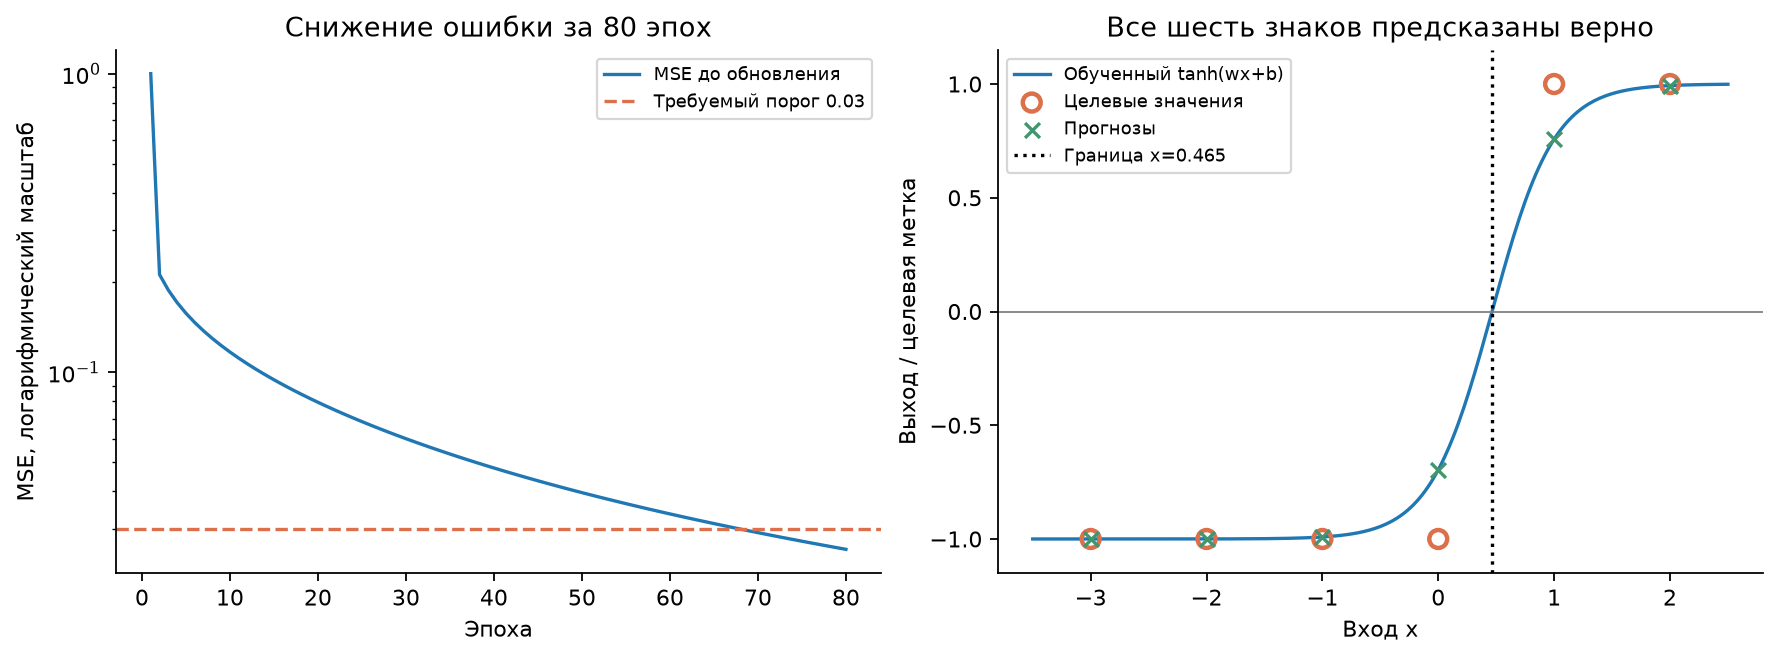

Вывод. Обе проверки условия выполнены: ошибка меньше 0.03, точность на шести объектах равна 1. Правильные знаки не означают нулевую MSE: непрерывные прогнозы ещё отличаются от целевых чисел. Оценка относится к обучающему набору.

Иллюстрация соответствует сохранённому запуску с шагом 0.2 и 80 эпохами. Основные расчёты и все проверки выполняются только средствами стандартной библиотеки Python.
